# 03 Molecular data

The molecular tables for the 203 patients, in the input formats of the BHK lab scripts (ICB_Van_Allen `Format_*.R`),
so NB04 can build the SummarizedExperiments with the lab's `get_*_se` functions. Methylation is built in its own
notebook (`03b_methylation.ipynb`) because it starts from raw IDAT files.

| Data | Source | Output | Format follows |
|---|---|---|---|
| Gene annotation | GENCODE v39 GTF (the version of the CBTN RNA files) | `annotation/Gencode.v39.annotation.RData` (`features_gene`) | ICB_Common `format_se()` input |
| RNA-seq | RSEM gene results, newest CBTN release | `EXPR_gene_tpm.csv`, `EXPR_gene_counts.csv` | `Format_EXPR.R` (genes x samples, `;`) |
| miRNA | HTG EdgeSeq counts, OpenPedCan v15 (raw counts, not normalized) | `MIRNA_counts.csv` | same as expression |
| Mutations | Consensus somatic MAF (all variant classes, coding and non-coding) | `SNV.csv`, `maf_combined.rds` | `Format_SNV.R` (`Sample;Gene;Chr;Pos;Ref;Alt;Effect;MutType`) |
| Copy number | CNVkit segments (also ControlFREEC and GATK, kept for a consensus later) | `CNA_seg.txt`, `CNA_gene.csv` | `Format_CNA_seg.R`, `Format_CNA_gene.R` |

**Two changes from the Van Allen scripts**

- **Columns are tumor biospecimens, not patients.** A patient can have more than one tumor sample. NB04 links
  biospecimens to patients with the sample map from NB01.
- **All mutation classes are kept.** Promoter and UTR variants are part of our question; the lab's coding-only filter
  sits in `get_snv_se.R` and is changed in NB04.

`CNA_gene.csv` holds the CNVkit log2 ratio of the segment over each gene's midpoint, not GISTIC calls (Van Allen used
GISTIC thresholds; we have no GISTIC run).

Outputs go to `data/procdata/03_molecular/` (not on GitHub). This notebook shows counts and plots only.

## 1. Setup

In [1]:
suppressPackageStartupMessages({
  library(data.table)
  library(ggplot2)
  library(patchwork)
})
options(width = 120, repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 120)

root <- Sys.getenv("PIXI_PROJECT_ROOT", unset = normalizePath(file.path("..", "..")))
RAWDATA <- file.path(root, "data", "rawdata")
FILES   <- file.path(RAWDATA, "cbtn_2026", "files")
NB01    <- file.path(root, "data", "procdata", "01_cohort")
OUT     <- file.path(root, "data", "procdata", "03_molecular")
ANNOT   <- file.path(root, "data", "procdata", "annotation")
dir.create(OUT, recursive = TRUE, showWarnings = FALSE)
dir.create(ANNOT, recursive = TRUE, showWarnings = FALSE)

SIX_TYPES <- c("Low-grade glioma", "Ependymoma", "Medulloblastoma", "Ganglioglioma",
               "High-grade glioma", "Adamantinomatous Craniopharyngioma")
SHORT <- setNames(c("LGG", "EPN", "MB", "GG", "HGG", "ACP"), SIX_TYPES)
TYPE_COLORS <- setNames(c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"), SIX_TYPES)
INK <- c(primary = "#0b0b0b", secondary = "#52514e", muted = "#898781", grid = "#e1e0d9")
theme_bp <- theme_minimal(base_size = 11) +
  theme(panel.grid.minor = element_blank(), panel.grid.major.y = element_blank(),
        panel.grid.major.x = element_line(colour = INK[["grid"]], linewidth = 0.3),
        axis.text = element_text(colour = INK[["secondary"]]), axis.title = element_text(colour = INK[["secondary"]]),
        plot.title = element_text(colour = INK[["primary"]], face = "bold"),
        plot.subtitle = element_text(colour = INK[["secondary"]]),
        strip.text = element_text(colour = INK[["primary"]], face = "bold", hjust = 0),
        legend.position = "top", legend.justification = "left",
        plot.background = element_rect(fill = "#fcfcfb", colour = NA))

# ';'-separated matrix with row names, as the lab's Format_EXPR.R writes it
write_matrix <- function(m, f) write.table(m, file.path(OUT, f), quote = FALSE, sep = ";", col.names = TRUE, row.names = TRUE)

sample_map <- fread(file.path(NB01, "sample_map.csv"))
pt <- fread(file.path(NB01, "cohort_patients.csv"))
sample_map[, tumor_type := pt$tumor_type[match(patient, pt$patient)]]
sample_map[, .(patients = uniqueN(patient), biospecimens = .N), by = assay]

assay,patients,biospecimens
<chr>,<int>,<int>
WGS,195,279
RNA-Seq,193,263
Methylation,202,240
miRNA-Seq,203,225


## 2. Gene annotation (GENCODE v39)

`format_se()` loads an `.RData` file with a `features_gene` table (one row per gene ID, with name, type and position).
We build it from the GENCODE v39 GTF, the version of the CBTN RNA files (checked in the gene-pair step: all 61,533
gene IDs match).

In [2]:
annot_file <- file.path(ANNOT, "Gencode.v39.annotation.RData")
if (!file.exists(annot_file)) {
  gtf <- fread(file.path(RAWDATA, "gencode_v39", "gencode.v39.annotation.gtf.gz"), sep = "\t", header = FALSE,
               skip = 5, quote = "", select = c(1, 3, 4, 5, 7, 9))[V3 == "gene"]
  attr <- function(key) sub(paste0('.*', key, ' "([^"]+)".*'), "\\1", gtf$V9)
  features_gene <- data.frame(gene_id = attr("gene_id"), gene_name = attr("gene_name"), gene_type = attr("gene_type"),
                              chr = gtf$V1, start = gtf$V4, end = gtf$V5, strand = gtf$V7)
  features_gene$length <- features_gene$end - features_gene$start + 1
  rownames(features_gene) <- features_gene$gene_id
  save(features_gene, file = annot_file)
}
load(annot_file)
cat("Genes:", nrow(features_gene), "\n")
as.data.table(features_gene)[, .N, by = gene_type][order(-N)][1:8]

Genes: 61533 


gene_type,N
<chr>,<int>
protein_coding,19982
lncRNA,17755
processed_pseudogene,10157
unprocessed_pseudogene,2605
misc_RNA,2212
snRNA,1901
miRNA,1879
TEC,1056


## 3. RNA-seq (RSEM)

One RSEM file per RNA biospecimen. We keep TPM and expected counts. `RNA_library` (poly-A or rRNA-depleted) comes from
OpenPedCan v15 where the biospecimen is there; it matters for later comparisons.

In [3]:
rna <- sample_map[assay == "RNA-Seq"]
stopifnot(!anyDuplicated(rna$biospecimen), grepl("rsem.genes.results.gz$", rna$files))
read_rsem <- function(f) fread(file.path(FILES, f), select = c("gene_id", "expected_count", "TPM"))
first_file <- read_rsem(rna$files[1])
genes <- first_file$gene_id
# RSEM IDs are "<gene_id>_<symbol>"; chrY PAR copies keep their "_PAR_Y" suffix
gene_ids <- sub("^(ENSG[0-9]+\\.[0-9]+(_PAR_Y)?)_.*$", "\\1", genes)
stopifnot(!anyDuplicated(gene_ids))
tpm <- counts <- matrix(NA_real_, nrow = length(genes), ncol = nrow(rna), dimnames = list(gene_ids, rna$biospecimen))
for (i in seq_len(nrow(rna))) {
  r <- read_rsem(rna$files[i])
  stopifnot(identical(r$gene_id, genes))
  tpm[, i] <- r$TPM
  counts[, i] <- r$expected_count
}
cat("RNA:", nrow(tpm), "genes x", ncol(tpm), "biospecimens;", sum(!rownames(tpm) %in% features_gene$gene_id),
    "gene IDs not in the v39 GTF (genes on unplaced scaffolds)\n")

hist <- fread(file.path(RAWDATA, "openpedcan_v15", "histologies.tsv"), na.strings = c("", "NA"),
              select = c("Kids_First_Biospecimen_ID", "RNA_library"))
rna[, RNA_library := hist$RNA_library[match(biospecimen, hist$Kids_First_Biospecimen_ID)]]
rna[, genes_tpm1 := colSums(tpm >= 1)]
rna[, .N, by = .(RNA_library)]

RNA: 61587 genes x 263 biospecimens; 54 gene IDs not in the v39 GTF (genes on unplaced scaffolds)


RNA_library,N
<chr>,<int>
stranded,237
poly-A stranded,22
NA,4


## 4. miRNA (HTG EdgeSeq)

OpenPedCan v15 stores raw counts as text. Rows starting with `CTRL_` are HTG control probes; they are kept in a
separate table and left out of the miRNA matrix. Normalization is open (question for Farnoosh), so this step keeps
raw counts.

In [4]:
mirna_raw <- readRDS(file.path(RAWDATA, "openpedcan_v15", "mirna-expression-counts.rds"))
mir_ids <- sample_map[assay == "miRNA-Seq", biospecimen]
stopifnot(mir_ids %in% colnames(mirna_raw))
m <- apply(as.matrix(mirna_raw[, mir_ids]), 2, as.numeric)
rownames(m) <- rownames(mirna_raw)
stopifnot(!anyNA(m), all(m == round(m)))
is_ctrl <- grepl("^CTRL_", rownames(m))
mirna_counts <- m[!is_ctrl, ]
mirna_ctrl <- m[is_ctrl, ]
cat("miRNA:", nrow(mirna_counts), "miRNAs x", ncol(mirna_counts), "biospecimens;", sum(is_ctrl), "control probes set aside\n")
mir <- sample_map[assay == "miRNA-Seq"]
mir[, total_counts := colSums(mirna_counts)[biospecimen]]
summary(mir$total_counts)

miRNA: 2096 miRNAs x 225 biospecimens; 6 control probes set aside


    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
    2743  1548607  2997083  2844709  3571219 18121352 

## 5. Mutations (consensus somatic MAF)

One MAF per WGS tumor biospecimen (consensus of the CBTN callers, annotated with VEP). All variant classes are kept.
`SNV.csv` follows `Format_SNV.R`; `maf_combined.rds` keeps more MAF columns (allele counts, HGVS, Ensembl gene ID)
for later steps.

In [5]:
wgs <- sample_map[assay == "WGS"]
maf_files <- wgs[, .(file = grep("consensus_somatic", unlist(strsplit(files, ";")), value = TRUE)), by = .(biospecimen, patient)]
keep_cols <- c("Hugo_Symbol", "Gene", "Chromosome", "Start_Position", "End_Position", "Variant_Classification",
               "Variant_Type", "Reference_Allele", "Tumor_Seq_Allele2", "Tumor_Sample_Barcode", "HGVSc", "HGVSp_Short",
               "t_depth", "t_ref_count", "t_alt_count", "n_depth", "Transcript_ID", "BIOTYPE")
maf <- rbindlist(lapply(maf_files$file, function(f) {
  d <- fread(file.path(FILES, f), skip = "Hugo_Symbol", sep = "\t", quote = "", colClasses = "character")
  d[, intersect(keep_cols, names(d)), with = FALSE]
}), fill = TRUE)
stopifnot(maf$Tumor_Sample_Barcode %in% wgs$biospecimen)
maf[, c("Start_Position", "End_Position", "t_depth", "t_ref_count", "t_alt_count") :=
      lapply(.SD, as.integer), .SDcols = c("Start_Position", "End_Position", "t_depth", "t_ref_count", "t_alt_count")]

CODING <- c("In_Frame_Del", "In_Frame_Ins", "Frame_Shift_Del", "Frame_Shift_Ins", "Missense_Mutation", "Nonsense_Mutation",
            "Nonstop_Mutation", "Splice_Site", "Translation_Start_Site")
maf[, class_group := fcase(Variant_Classification %in% CODING, "Coding (kept by the lab filter)",
                           Variant_Classification %in% c("5'Flank", "5'UTR"), "Promoter side (5' flank, 5' UTR)",
                           default = "Other non-coding (intron, IGR, 3' side, silent, RNA)")]
cat("Variants:", nrow(maf), "in", uniqueN(maf$Tumor_Sample_Barcode), "WGS biospecimens with a MAF file (",
    nrow(wgs) - uniqueN(maf$Tumor_Sample_Barcode), "WGS biospecimens have copy-number files only )\n\n")
maf[, .(variants = .N, per_sample_median = as.double(median(table(factor(Tumor_Sample_Barcode, levels = unique(maf$Tumor_Sample_Barcode)))))),
    by = class_group]

Variants: 865354 in 275 WGS biospecimens with a MAF file ( 4 WGS biospecimens have copy-number files only )



class_group,variants,per_sample_median
<chr>,<int>,<dbl>
"Other non-coding (intron, IGR, 3' side, silent, RNA)",799892,1663
"Promoter side (5' flank, 5' UTR)",55448,121
Coding (kept by the lab filter),10014,16


In [6]:
# Format_SNV.R layout; Sample = biospecimen
snv <- maf[, .(Sample = Tumor_Sample_Barcode, Gene = Hugo_Symbol, Chr = Chromosome, Pos = Start_Position,
               Ref = fifelse(Reference_Allele == "-", "", Reference_Allele),
               Alt = fifelse(Tumor_Seq_Allele2 == "-", "", Tumor_Seq_Allele2),
               Effect = Variant_Classification)]
snv[, MutType := fifelse(nchar(Ref) != nchar(Alt), "INDEL", "SNV")]
snv[, .N, by = MutType]

MutType,N
<chr>,<int>
SNV,646369
INDEL,218985


## 6. Copy number

CNVkit segments (`.call.seg`, log2 ratio per segment) are the main copy-number table, as in `Format_CNA_seg.R`. The
gene-level table gives each gene the log2 ratio of the segment over its midpoint. ControlFREEC and GATK segments are
saved too, for a consensus call later.

In [7]:
cnv_files <- wgs[, .(file = unlist(strsplit(files, ";"))), by = .(biospecimen, patient)]
read_caller <- function(pattern, reader) {
  fl <- cnv_files[grepl(pattern, file)]
  rbindlist(lapply(seq_len(nrow(fl)), function(i) reader(file.path(FILES, fl$file[i]))[, biospecimen := fl$biospecimen[i]]))
}
seg <- read_caller("\\.call\\.seg$", function(f) fread(f, colClasses = list(character = "ID")))
stopifnot(seg$ID == seg$biospecimen)
freec <- read_caller("controlfreec", function(f) fread(f))
gatk <- read_caller("gatk_cnv", function(f) fread(cmd = NULL, file = f, skip = "CONTIG"))
data.table(caller = c("CNVkit", "ControlFREEC", "GATK"),
           biospecimens = c(uniqueN(seg$biospecimen), uniqueN(freec$biospecimen), uniqueN(gatk$biospecimen)),
           segments = c(nrow(seg), nrow(freec), nrow(gatk)))

caller,biospecimens,segments
<chr>,<int>,<int>
CNVkit,275,457677
ControlFREEC,275,310623
GATK,272,183121


In [8]:
# Gene-level log2 ratio: segment over the gene midpoint (autosomes and X/Y as given)
g <- data.table(gene_id = features_gene$gene_id, chrom = features_gene$chr,
                mid = as.integer((features_gene$start + features_gene$end) / 2))
g[, `:=`(s = mid, e = mid)]
sg <- seg[, .(biospecimen, chrom, s = as.integer(loc.start), e = as.integer(loc.end), seg.mean)]
setkey(sg, chrom, s, e)
hit <- foverlaps(g, sg, by.x = c("chrom", "s", "e"), type = "within", nomatch = NULL)
cna_gene <- as.matrix(dcast(hit, gene_id ~ biospecimen, value.var = "seg.mean", fun.aggregate = mean), rownames = "gene_id")
cat("Gene-level copy number:", nrow(cna_gene), "genes x", ncol(cna_gene), "biospecimens;",
    round(100 * mean(is.na(cna_gene)), 1), "% gene-sample pairs without a segment\n")

# Fraction of the genome in a gained or lost segment (|log2| > 0.2), per biospecimen
cna_fga <- seg[, .(fga = sum((loc.end - loc.start)[abs(seg.mean) > 0.2]) / sum(loc.end - loc.start)), by = biospecimen]

Gene-level copy number: 61450 genes x 275 biospecimens; 0 % gene-sample pairs without a segment


## 7. Plots: one look at each data type

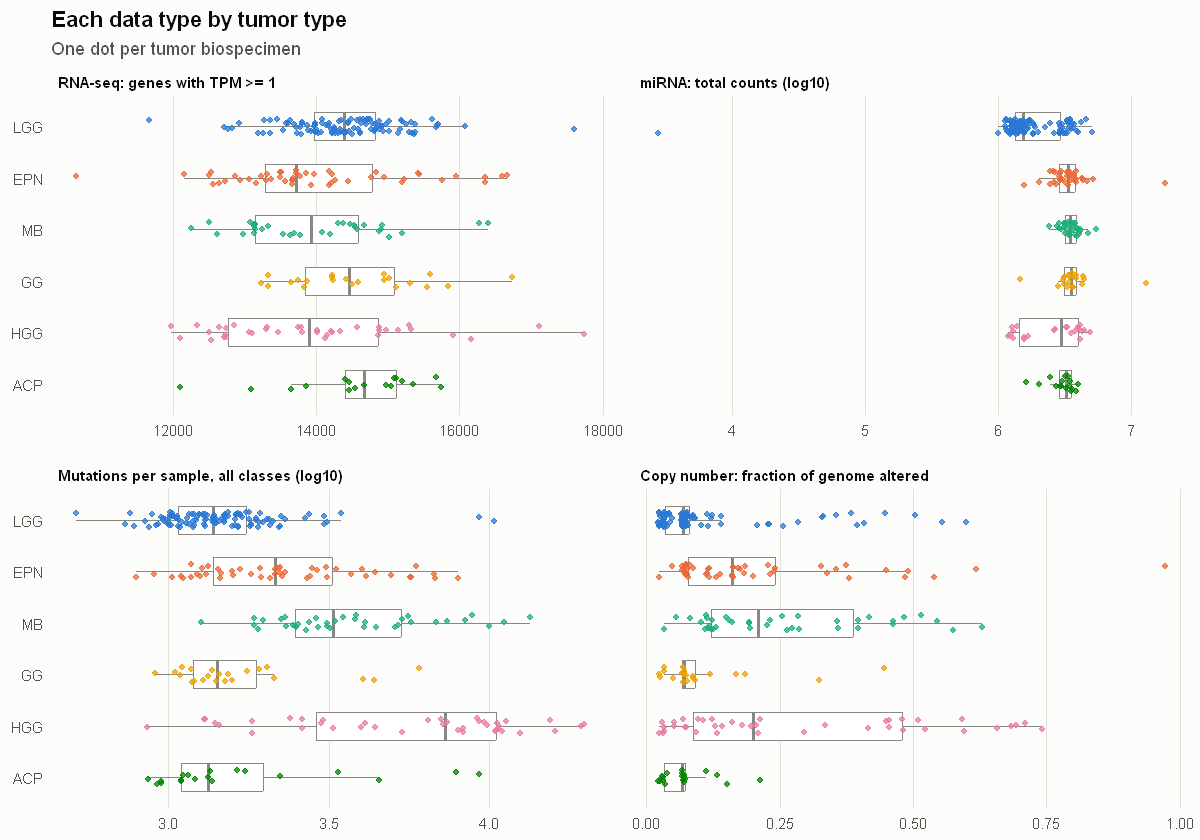

In [9]:
bios <- rbind(
  rna[, .(biospecimen, tumor_type, panel = "RNA-seq: genes with TPM >= 1", value = genes_tpm1)],
  mir[, .(biospecimen, tumor_type, panel = "miRNA: total counts (log10)", value = log10(total_counts))],
  maf[, .(value = log10(.N)), by = .(biospecimen = Tumor_Sample_Barcode)][
    , `:=`(tumor_type = sample_map$tumor_type[match(biospecimen, sample_map$biospecimen)],
           panel = "Mutations per sample, all classes (log10)")],
  merge(cna_fga, unique(sample_map[assay == "WGS", .(biospecimen, tumor_type)]), by = "biospecimen")[
    , .(biospecimen, tumor_type, panel = "Copy number: fraction of genome altered", value = fga)],
  fill = TRUE)
bios <- bios[tumor_type %in% SIX_TYPES]
bios[, tumor_type := factor(tumor_type, levels = rev(SIX_TYPES))]
bios[, panel := factor(panel, levels = unique(panel))]

ggplot(bios, aes(value, tumor_type, colour = tumor_type)) +
  geom_boxplot(outlier.shape = NA, width = 0.55, colour = INK[["muted"]]) +
  geom_jitter(height = 0.15, width = 0, size = 1.3, alpha = 0.75) +
  facet_wrap(~ panel, scales = "free_x", ncol = 2) +
  scale_colour_manual(values = TYPE_COLORS, guide = "none") +
  scale_y_discrete(labels = SHORT) +
  labs(title = "Each data type by tumor type", subtitle = "One dot per tumor biospecimen", x = NULL, y = NULL) +
  theme_bp + theme(panel.spacing = unit(14, "pt"))

In [10]:
bios[, .(biospecimens = .N, median = signif(median(value), 3)), by = .(panel, tumor_type = SHORT[as.character(tumor_type)])][
  order(panel, match(tumor_type, SHORT))] |> dcast(tumor_type ~ panel, value.var = "median")

tumor_type,RNA-seq: genes with TPM >= 1,miRNA: total counts (log10),"Mutations per sample, all classes (log10)",Copy number: fraction of genome altered
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ACP,14700,6.51,3.12,0.0678
EPN,13700,6.53,3.33,0.1610
GG,14500,6.55,3.15,0.0701
HGG,13900,6.47,3.86,0.2000
LGG,14400,6.19,3.14,0.0689
MB,13900,6.54,3.51,0.2100


### Mutation classes by tumor type

Most somatic variants in WGS are outside coding sequence. The lab filter keeps only the coding classes; the promoter
side (5' flank and 5' UTR) is what that filter would drop.

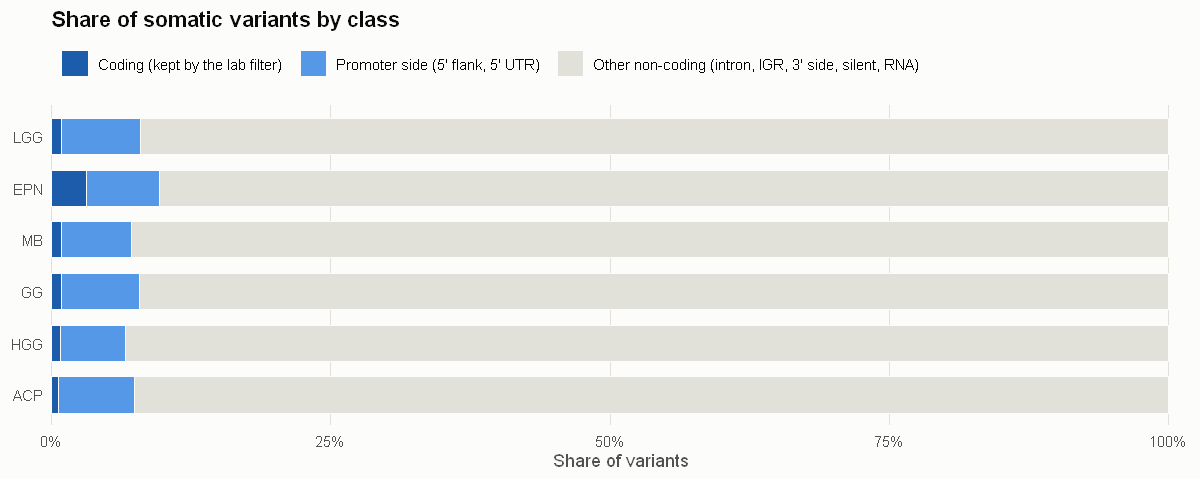

In [11]:
options(repr.plot.width = 10, repr.plot.height = 4)
mc <- maf[, .N, by = .(biospecimen = Tumor_Sample_Barcode, class_group)]
mc[, tumor_type := sample_map$tumor_type[match(biospecimen, sample_map$biospecimen)]]
mc <- mc[tumor_type %in% SIX_TYPES, .(variants = sum(N)), by = .(tumor_type, class_group)]
mc[, share := variants / sum(variants), by = tumor_type]
mc[, tumor_type := factor(tumor_type, levels = rev(SIX_TYPES))]
lv <- c("Coding (kept by the lab filter)", "Promoter side (5' flank, 5' UTR)", "Other non-coding (intron, IGR, 3' side, silent, RNA)")
mc[, class_group := factor(class_group, levels = rev(lv))]
ggplot(mc, aes(share, tumor_type, fill = class_group)) +
  geom_col(width = 0.7, colour = "#fcfcfb", linewidth = 0.5) +
  scale_fill_manual(values = setNames(c("#1c5cab", "#5598e7", "#e1e0d9"), lv), breaks = lv, name = NULL) +
  scale_x_continuous(labels = scales::percent, expand = expansion(mult = c(0, 0.02))) +
  scale_y_discrete(labels = SHORT) +
  labs(title = "Share of somatic variants by class", x = "Share of variants", y = NULL) +
  theme_bp

In [12]:
dcast(mc, tumor_type ~ class_group, value.var = "variants")[order(match(tumor_type, SIX_TYPES))]

tumor_type,"Other non-coding (intron, IGR, 3' side, silent, RNA)","Promoter side (5' flank, 5' UTR)",Coding (kept by the lab filter)
<fct>,<int>,<int>,<int>
Low-grade glioma,162235,12385,1582
Ependymoma,114765,8348,3968
Medulloblastoma,154634,10474,1424
Ganglioglioma,38267,2913,353
High-grade glioma,273931,17292,2267
Adamantinomatous Craniopharyngioma,40872,3000,269


## 8. Save outputs

In [13]:
write_matrix(tpm, "EXPR_gene_tpm.csv")
write_matrix(counts, "EXPR_gene_counts.csv")
write_matrix(mirna_counts, "MIRNA_counts.csv")
write_matrix(cna_gene, "CNA_gene.csv")
write.table(snv, file.path(OUT, "SNV.csv"), quote = FALSE, sep = ";", col.names = TRUE, row.names = FALSE)
write.table(seg[, .(ID, chrom, loc.start, loc.end, num.mark, seg.mean)], file.path(OUT, "CNA_seg.txt"),
            quote = FALSE, sep = "\t", col.names = TRUE, row.names = FALSE)

# Faster copies and the extra tables for NB04 and later steps
saveRDS(list(tpm = tpm, counts = counts), file.path(OUT, "expr.rds"))
saveRDS(list(counts = mirna_counts, control_probes = mirna_ctrl), file.path(OUT, "mirna.rds"))
saveRDS(maf, file.path(OUT, "maf_combined.rds"))
saveRDS(list(cnvkit = seg, controlfreec = freec, gatk = gatk, fga = cna_fga), file.path(OUT, "cnv_segments.rds"))

# One row per biospecimen with what this step measured on it
sheet <- rbind(rna[, .(biospecimen, patient, sample_id, assay, tumor_type, RNA_library, genes_tpm1)],
               mir[, .(biospecimen, patient, sample_id, assay, tumor_type, mirna_total_counts = total_counts)],
               wgs[, .(biospecimen, patient, sample_id, assay, tumor_type,
                       has_maf = biospecimen %in% maf$Tumor_Sample_Barcode,
                       n_variants = maf[, .N, by = Tumor_Sample_Barcode][match(wgs$biospecimen, Tumor_Sample_Barcode), N],
                       fga = cna_fga$fga[match(wgs$biospecimen, cna_fga$biospecimen)])], fill = TRUE)
fwrite(sheet, file.path(OUT, "samples_03.csv"))

files_out <- list.files(OUT)
data.table(file = files_out, MB = round(file.size(file.path(OUT, files_out)) / 1e6, 1))

file,MB
<chr>,<dbl>
CNA_gene.csv,183.8
CNA_seg.txt,23.1
cnv_segments.rds,17.5
expr.rds,47.8
EXPR_gene_counts.csv,50.7
EXPR_gene_tpm.csv,58.8
maf_combined.rds,25.3
mirna.rds,0.8
MIRNA_counts.csv,1.3


In [14]:
sessionInfo()

R version 4.5.3 (2026-03-11 ucrt)
Platform: x86_64-w64-mingw32/x64
Running under: Windows 11 x64 (build 26200)

Matrix products: default
  LAPACK version 3.12.1

locale:
[1] LC_COLLATE=English_Canada.utf8  LC_CTYPE=English_Canada.utf8    LC_MONETARY=English_Canada.utf8
[4] LC_NUMERIC=C                    LC_TIME=English_Canada.utf8    

time zone: America/Toronto
tzcode source: internal

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] patchwork_1.3.2     ggplot2_4.0.3       data.table_1.18.6.1

loaded via a namespace (and not attached):
 [1] crayon_1.5.3       vctrs_0.7.3        cli_3.6.6          rlang_1.3.0        generics_0.1.4     S7_0.2.2          
 [7] jsonlite_2.0.0     labeling_0.4.3     glue_1.8.1         htmltools_0.5.9    IRdisplay_1.1      IRkernel_1.3.2    
[13] scales_1.4.0       grid_4.5.3         evaluate_1.0.5     tibble_3.3.1       fastmap_1.2.0      base64enc_0.1-6   
[19] lifecycle_1.0.5